# Notebook 1 — Flow Matching desde cero

**Aprendizaje Profundo · Presentación: Flow Matching & Rectified Flows**

En este cuaderno implementamos **Conditional Flow Matching (CFM)** [Lipman et al., 2023] en unas 30 líneas de PyTorch y lo usamos para transformar ruido gaussiano en distribuciones 2D.

**Objetivos**
1. Entender qué es un *camino de probabilidad* $p_t$ y un *campo de velocidades* $v_t$.
2. Entrenar un flujo continuo **sin simular la ODE** (*simulation-free*).
3. Muestrear integrando la ODE y estudiar el compromiso **calidad ↔ número de pasos (NFE)**.
4. Ver que de la velocidad aprendida se obtiene el **score** y el **denoiser** de un modelo de difusión.

**Convención** (la de Lipman et al. y Liu et al.): $t=0$ es **ruido** $x_0\sim\mathcal N(0,I)$ y $t=1$ son **datos** $x_1\sim q$.
*(Ojo: Stable Diffusion 3 y muchos códigos de difusión usan la convención contraria.)*

> Se ejecuta en CPU en ~3–4 minutos. En Colab: *Entorno de ejecución → Ejecutar todo*.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import animation

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

SAVE_FIGS = True          # guarda las figuras en ./figuras para las diapositivas
FIG_DIR = "figuras"
import os; os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 11})
C_NOISE, C_DATA, C_TRAJ = "#9aa5b1", "#d1495b", "#00798c"

def savefig(name):
    if SAVE_FIGS:
        plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight", transparent=False)

device: cpu | torch 2.15.0+cpu


## 1. Datos de juguete en 2D

Tres distribuciones objetivo $q(x_1)$ clásicas. La distribución inicial $p_0$ es siempre $\mathcal N(0, I)$.

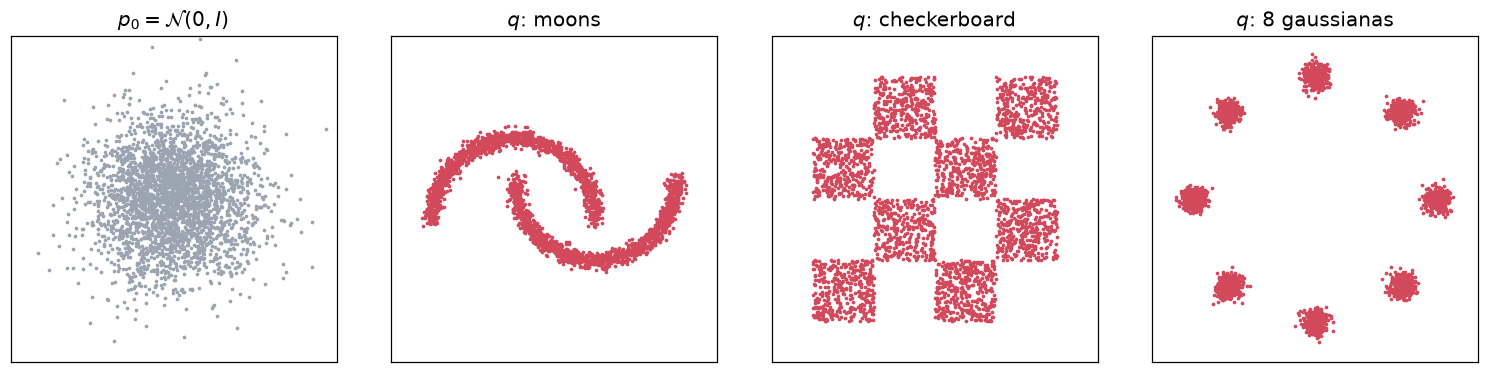

In [2]:
def sample_moons(n, noise=0.05):
    t = torch.rand(n) * math.pi
    upper = torch.rand(n) < 0.5
    x = torch.where(upper, torch.cos(t), 1 - torch.cos(t))
    y = torch.where(upper, torch.sin(t), 0.5 - torch.sin(t))
    pts = torch.stack([x, y], 1) + noise * torch.randn(n, 2)
    return (pts - torch.tensor([0.5, 0.25])) * 2.0

def sample_checkerboard(n):
    x1 = torch.rand(n) * 4 - 2
    x2 = torch.rand(n) - torch.randint(0, 2, (n,)).float() * 2
    x2 = x2 + (torch.floor(x1) % 2)
    return torch.stack([x1, x2], 1) * 1.5

def sample_8gaussians(n, r=3.0, std=0.15):
    ang = torch.randint(0, 8, (n,)) * (2 * math.pi / 8)
    centers = torch.stack([torch.cos(ang), torch.sin(ang)], 1) * r
    return centers + std * torch.randn(n, 2)

DATASETS = {"moons": sample_moons, "checkerboard": sample_checkerboard, "8 gaussianas": sample_8gaussians}

fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))
axs[0].scatter(*torch.randn(3000, 2).T, s=2, c=C_NOISE); axs[0].set_title(r"$p_0=\mathcal{N}(0,I)$")
for ax, (name, f) in zip(axs[1:], DATASETS.items()):
    ax.scatter(*f(3000).T, s=2, c=C_DATA); ax.set_title(f"$q$: {name}")
for ax in axs: ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("nb1_datasets"); plt.show()

## 2. La idea: un camino de probabilidad y su campo de velocidades

Un **flujo continuo** está definido por una ODE
$$\frac{d x_t}{dt} = v_\theta(x_t, t), \qquad x_0 \sim p_0 .$$
El campo $v_\theta$ "empuja" la masa de probabilidad: si las partículas siguen la ODE, su densidad $p_t$ cumple la **ecuación de continuidad** $\partial_t p_t + \nabla\!\cdot(p_t v_t) = 0$.

**Flow Matching** propone fijar *primero* un camino $p_t$ que vaya de $p_0$ a $q$, y luego **regresar** el campo $u_t$ que lo genera:
$$\mathcal L_{FM}(\theta) = \mathbb E_{t, x\sim p_t}\,\|v_\theta(x,t) - u_t(x)\|^2 .$$
El problema es que ni $p_t$ ni $u_t$ son tratables. **El truco (CFM)**: construimos $p_t$ como mezcla de caminos *condicionales* sencillos, uno por cada dato $x_1$:
$$x_t = (1-t)\,x_0 + t\,x_1, \qquad u_t(x_t\mid x_1) = \frac{d x_t}{dt} = x_1 - x_0 .$$
**Teorema** (Lipman et al., 2023): $\nabla_\theta \mathcal L_{CFM} = \nabla_\theta \mathcal L_{FM}$, con
$$\boxed{\mathcal L_{CFM}(\theta) = \mathbb E_{t\sim U[0,1],\,x_0\sim p_0,\,x_1\sim q}\,\big\|v_\theta(x_t,t) - (x_1 - x_0)\big\|^2}$$

Visualicemos el camino: tomamos pares $(x_0, x_1)$ **independientes** e interpolamos.

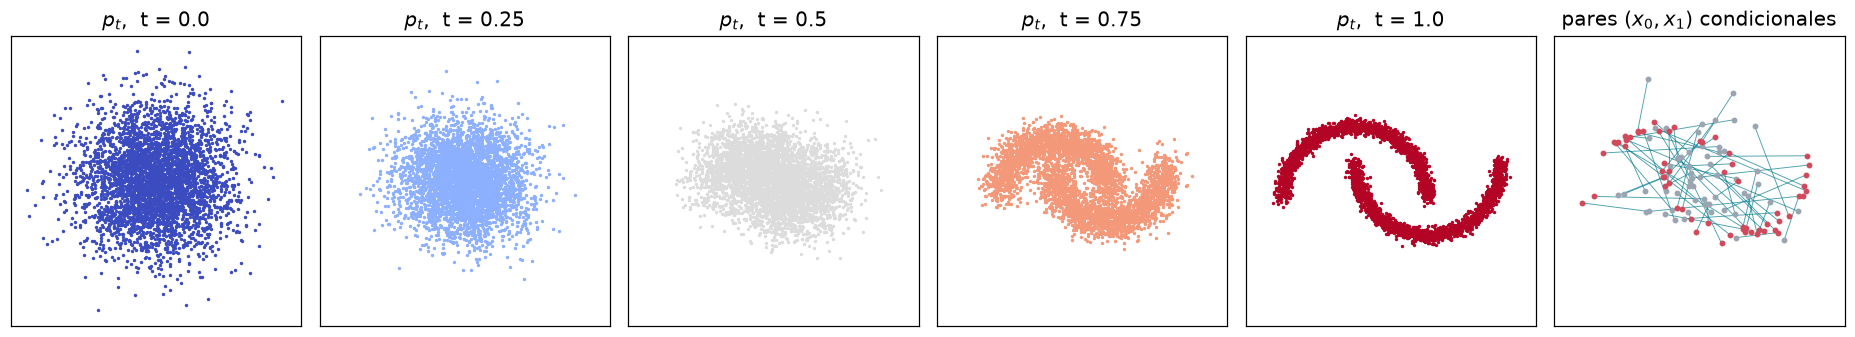

In [3]:
sample_data = DATASETS["moons"]          # <- cambia aquí el dataset: "checkerboard", "8 gaussianas"

n = 4000
x0, x1 = torch.randn(n, 2), sample_data(n)
ts = [0.0, 0.25, 0.5, 0.75, 1.0]
fig, axs = plt.subplots(1, len(ts) + 1, figsize=(17, 3.2))
for ax, t in zip(axs, ts):
    xt = (1 - t) * x0 + t * x1
    ax.scatter(*xt.T, s=1.5, c=[plt.cm.coolwarm(t)])
    ax.set_title(f"$p_t$,  t = {t}")
# líneas rectas entre pares (x0, x1): ¡se cruzan!
ax = axs[-1]
for i in range(60):
    ax.plot([x0[i, 0], x1[i, 0]], [x0[i, 1], x1[i, 1]], c=C_TRAJ, lw=0.6, alpha=0.7)
ax.scatter(*x0[:60].T, s=8, c=C_NOISE, zorder=3); ax.scatter(*x1[:60].T, s=8, c=C_DATA, zorder=3)
ax.set_title("pares $(x_0,x_1)$ condicionales")
for ax in axs: ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("nb1_prob_path"); plt.show()

Observa la última figura: las rectas condicionales **se cruzan**. En un punto $x$ por el que pasan varias rectas, el campo marginal es su **promedio**:
$$u_t(x) = \mathbb E\,[\,x_1 - x_0 \mid x_t = x\,].$$
Eso es justamente lo que aprende la red al minimizar el error cuadrático (la esperanza condicional es el minimizador del MSE). Consecuencia: las trayectorias de la ODE aprendida **no se cruzan** y, por tanto, son **curvas** → volveremos a esto en el Notebook 2 (*Rectified Flow*).

## 3. El modelo: un MLP $v_\theta(x, t)$

In [4]:
class TimeEmbedding(nn.Module):
    # Embedding sinusoidal de t (como en Transformers / modelos de difusión)
    def __init__(self, dim=32):
        super().__init__()
        self.register_buffer("freqs", torch.exp(torch.linspace(0, math.log(1000), dim // 2)))
    def forward(self, t):
        a = t[:, None] * self.freqs[None]
        return torch.cat([torch.sin(a), torch.cos(a)], dim=1)

class VelocityMLP(nn.Module):
    def __init__(self, dim=2, hidden=256, temb=32):
        super().__init__()
        self.temb = TimeEmbedding(temb)
        self.net = nn.Sequential(
            nn.Linear(dim + temb, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, dim))
    def forward(self, x, t):
        return self.net(torch.cat([x, self.temb(t)], dim=1))

print(sum(p.numel() for p in VelocityMLP().parameters()), "parámetros")

141058 parámetros


## 4. Entrenamiento con Conditional Flow Matching

El bucle entero. Fíjate en que **no hay ninguna ODE** dentro del entrenamiento: sólo muestrear $(t, x_0, x_1)$, interpolar y hacer regresión.

iter  1000 | loss 1.9699


iter  2000 | loss 1.9024


iter  3000 | loss 1.9011


iter  4000 | loss 1.8887


iter  5000 | loss 1.8907


iter  6000 | loss 1.8837
entrenado en 14.3s


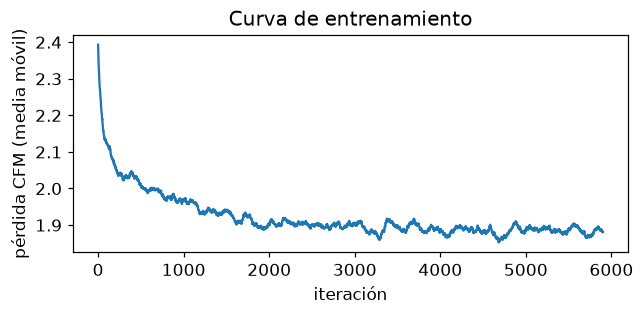

In [5]:
def train_cfm(sample_data, iters=6000, batch=512, lr=1e-3, seed=0, log_every=1000):
    torch.manual_seed(seed)
    model = VelocityMLP().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters)
    losses = []
    for it in range(iters):
        x1 = sample_data(batch).to(device)               # datos
        x0 = torch.randn_like(x1)                        # ruido
        t = torch.rand(batch, device=device)             # t ~ U[0,1]
        xt = (1 - t[:, None]) * x0 + t[:, None] * x1     # punto del camino condicional
        target = x1 - x0                                 # velocidad condicional
        loss = ((model(xt, t) - target) ** 2).mean()     # regresión
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        losses.append(loss.item())
        if (it + 1) % log_every == 0:
            print(f"iter {it+1:5d} | loss {np.mean(losses[-200:]):.4f}")
    return model, losses

t0 = time.time()
model, losses = train_cfm(sample_data)
print(f"entrenado en {time.time()-t0:.1f}s")

plt.figure(figsize=(6, 3))
plt.plot(np.convolve(losses, np.ones(100) / 100, mode="valid"))
plt.xlabel("iteración"); plt.ylabel("pérdida CFM (media móvil)"); plt.title("Curva de entrenamiento")
plt.tight_layout(); savefig("nb1_loss"); plt.show()

**Pregunta para la clase:** ¿por qué la pérdida **no baja a cero**?

<details><summary>Respuesta</summary>

El objetivo $x_1 - x_0$ es *condicional*: para un mismo $(x_t, t)$ hay muchos pares $(x_0,x_1)$ posibles. La red sólo puede predecir su media; la varianza $\mathbb E\,\|x_1-x_0 - u_t(x_t)\|^2$ es irreducible. Por eso $\mathcal L_{CFM} = \mathcal L_{FM} + \text{cte}$ (¡misma solución, mismos gradientes!).
</details>

## 5. Muestreo: integrar la ODE

Una vez entrenado, generamos integrando $\dot x = v_\theta(x,t)$ desde $t=0$ hasta $t=1$. Usamos dos integradores:
- **Euler** (1 evaluación de la red por paso): $x_{t+h} = x_t + h\, v_\theta(x_t, t)$
- **Punto medio / RK2** (2 evaluaciones por paso).

Medimos el coste en **NFE** = *number of function evaluations*.

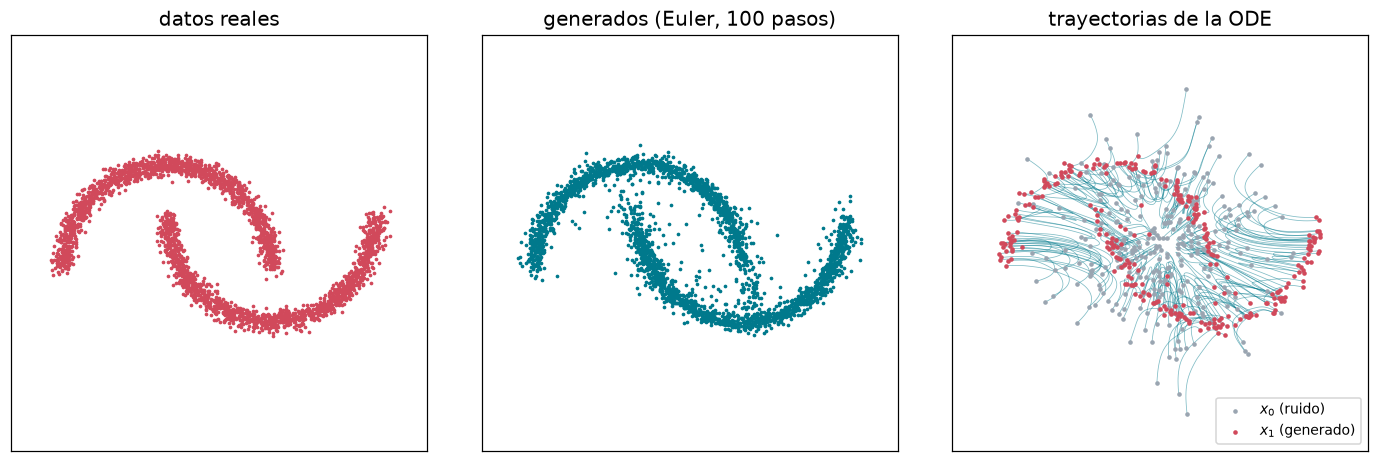

In [6]:
@torch.no_grad()
def sample_ode(model, x0, steps=100, method="euler", return_traj=False):
    x, h = x0.clone().to(device), 1.0 / steps
    traj = [x.cpu()]
    for i in range(steps):
        t = torch.full((x.shape[0],), i * h, device=device)
        if method == "euler":
            x = x + h * model(x, t)
        elif method == "midpoint":
            x_mid = x + 0.5 * h * model(x, t)
            x = x + h * model(x_mid, t + 0.5 * h)
        if return_traj: traj.append(x.cpu())
    return (x.cpu(), torch.stack(traj)) if return_traj else x.cpu()

z = torch.randn(3000, 2)
xs, traj = sample_ode(model, z, steps=100, return_traj=True)

fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
axs[0].scatter(*sample_data(3000).T, s=2, c=C_DATA); axs[0].set_title("datos reales")
axs[1].scatter(*xs.T, s=2, c=C_TRAJ); axs[1].set_title("generados (Euler, 100 pasos)")
for i in range(300):
    axs[2].plot(traj[:, i, 0], traj[:, i, 1], c=C_TRAJ, lw=0.5, alpha=0.5)
axs[2].scatter(*traj[0, :300].T, s=4, c=C_NOISE, zorder=3, label="$x_0$ (ruido)")
axs[2].scatter(*traj[-1, :300].T, s=4, c=C_DATA, zorder=3, label="$x_1$ (generado)")
axs[2].legend(loc="lower right", fontsize=9); axs[2].set_title("trayectorias de la ODE")
for ax in axs: ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("nb1_samples_traj"); plt.show()

Las trayectorias **no se cruzan** (es una ODE con campo suave: unicidad de soluciones) y muchas son **curvas**. Esto tiene una consecuencia práctica directa en el número de pasos necesario.

## 6. El campo de velocidades aprendido, en el tiempo

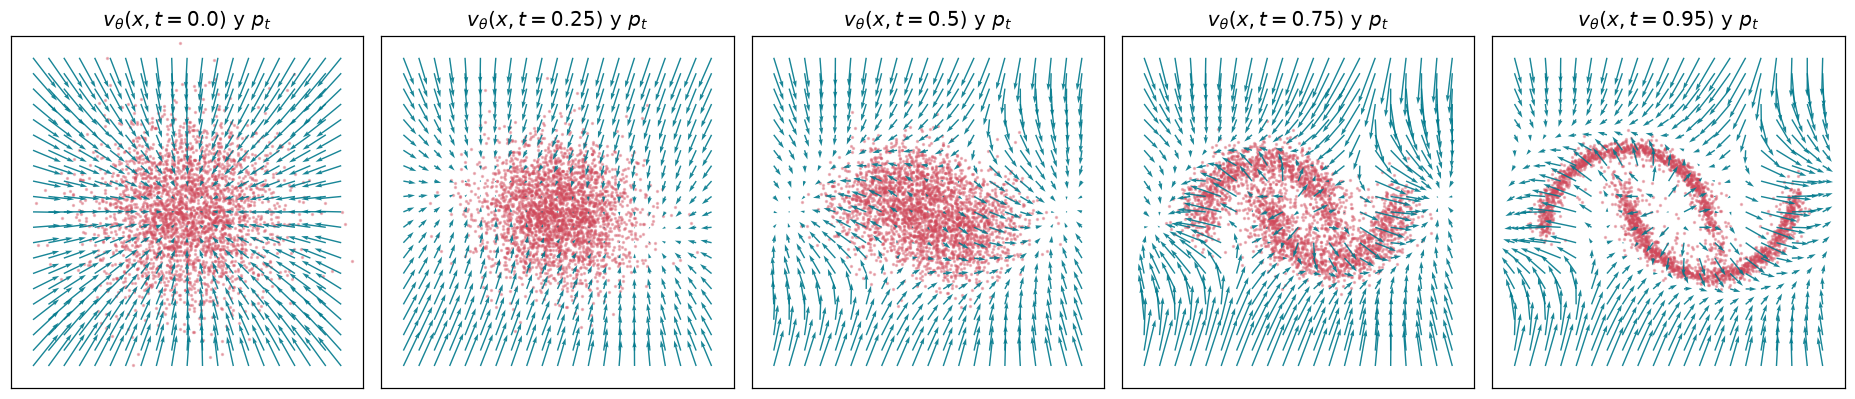

In [7]:
g = torch.linspace(-3.5, 3.5, 21)
GX, GY = torch.meshgrid(g, g, indexing="xy")
grid = torch.stack([GX.flatten(), GY.flatten()], 1)
ts = [0.0, 0.25, 0.5, 0.75, 0.95]
fig, axs = plt.subplots(1, len(ts), figsize=(17, 3.6))
for ax, t in zip(axs, ts):
    k = int(round(t * 100))
    with torch.no_grad():
        v = model(grid.to(device), torch.full((grid.shape[0],), t, device=device)).cpu()
    ax.scatter(*traj[k].T, s=1.5, c=C_DATA, alpha=0.35)
    ax.quiver(grid[:, 0], grid[:, 1], v[:, 0], v[:, 1], color=C_TRAJ, alpha=0.9, scale=40, width=0.004)
    ax.set_title(f"$v_\\theta(x, t={t})$ y $p_t$")
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("nb1_vector_field"); plt.show()

### Animación (GIF) del transporte
Genera `figuras/nb1_flow.gif`, que se puede insertar directamente en PowerPoint.

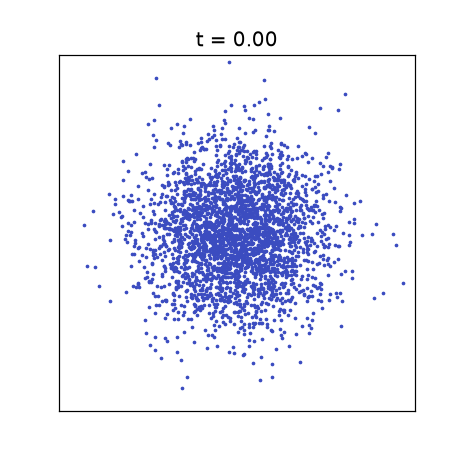

In [8]:
fig, ax = plt.subplots(figsize=(4.2, 4.2))
sc = ax.scatter(*traj[0].T, s=2, c=C_TRAJ)
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
title = ax.set_title("t = 0.00")
frames = list(range(0, 101, 2)) + [100] * 15          # pausa al final
def update(k):
    sc.set_offsets(traj[k].numpy()); title.set_text(f"t = {k/100:.2f}")
    sc.set_color(plt.cm.coolwarm(k / 100)); return sc, title
anim = animation.FuncAnimation(fig, update, frames=frames, interval=60, blit=False)
if SAVE_FIGS:
    anim.save(f"{FIG_DIR}/nb1_flow.gif", writer=animation.PillowWriter(fps=16))
plt.close(fig)
try:
    from IPython.display import Image, display
    display(Image(filename=f"{FIG_DIR}/nb1_flow.gif"))
except Exception as e:
    print(e)

## 7. Calidad vs. número de pasos (NFE)

Para medir la calidad usamos la **distancia de Wasserstein deslizada** (*sliced Wasserstein*, SW₂) entre muestras generadas y reales: proyectamos sobre muchas direcciones aleatorias y comparamos las distribuciones 1D ordenadas. Más bajo = mejor.

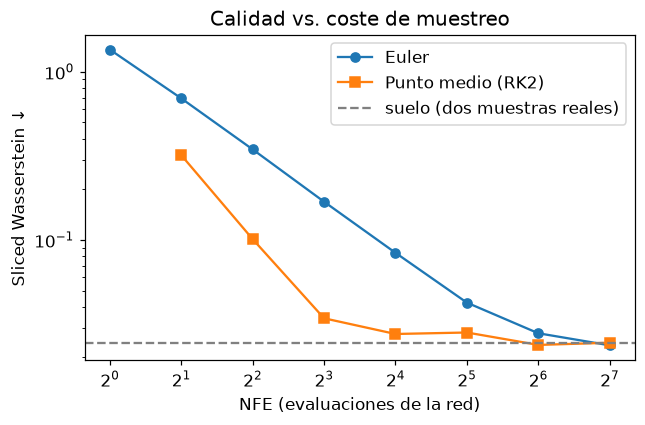

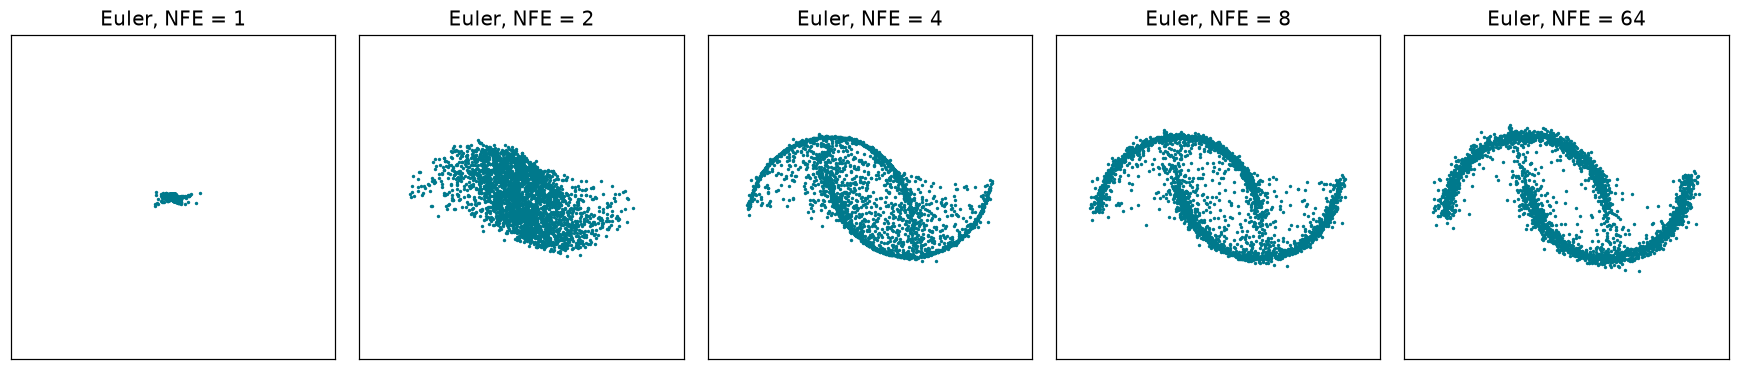

In [9]:
def sliced_wasserstein(a, b, n_proj=256, seed=0):
    gen = torch.Generator().manual_seed(seed)
    d = torch.randn(a.shape[1], n_proj, generator=gen); d = d / d.norm(dim=0, keepdim=True)
    pa, pb = torch.sort(a @ d, dim=0)[0], torch.sort(b @ d, dim=0)[0]
    return ((pa - pb) ** 2).mean().sqrt().item()

N = 5000
z = torch.randn(N, 2, generator=torch.Generator().manual_seed(1))
ref = sample_data(N)
ref2 = sample_data(N)
floor = sliced_wasserstein(ref, ref2)     # "suelo" por ruido de muestreo

nfes = [1, 2, 4, 8, 16, 32, 64, 128]
res = {"euler": [], "midpoint": []}
for nfe in nfes:
    res["euler"].append(sliced_wasserstein(sample_ode(model, z, steps=nfe, method="euler"), ref))
    if nfe >= 2:
        res["midpoint"].append(sliced_wasserstein(sample_ode(model, z, steps=nfe // 2, method="midpoint"), ref))

plt.figure(figsize=(6, 4))
plt.plot(nfes, res["euler"], "o-", label="Euler")
plt.plot(nfes[1:], res["midpoint"], "s-", label="Punto medio (RK2)")
plt.axhline(floor, ls="--", c="gray", label="suelo (dos muestras reales)")
plt.xscale("log", base=2); plt.yscale("log")
plt.xlabel("NFE (evaluaciones de la red)"); plt.ylabel("Sliced Wasserstein ↓")
plt.title("Calidad vs. coste de muestreo"); plt.legend()
plt.tight_layout(); savefig("nb1_nfe_quality"); plt.show()

fig, axs = plt.subplots(1, 5, figsize=(16, 3.3))
for ax, nfe in zip(axs, [1, 2, 4, 8, 64]):
    ax.scatter(*sample_ode(model, z[:3000], steps=nfe).T, s=1.5, c=C_TRAJ)
    ax.set_title(f"Euler, NFE = {nfe}")
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("nb1_nfe_grid"); plt.show()

Con **1 paso** de Euler el modelo produce, literalmente, $x_0 + v_\theta(x_0, 0) \approx \mathbb E[x_1]$ "desplazado": una mancha borrosa. Las trayectorias curvas obligan a dar muchos pasos. **¿Podemos enderezarlas?** → Notebook 2.

## 8. Conexión con modelos de difusión: de la velocidad al *score*

Con el camino lineal y $x_0\sim\mathcal N(0,I)$, condicionado a $x_1$ tenemos $x_t\mid x_1 \sim \mathcal N(t\,x_1,\,(1-t)^2 I)$: **¡es exactamente un modelo de difusión gaussiano!** (con *schedule* $\alpha_t = t$, $\sigma_t = 1-t$). Despejando de $v = \mathbb E[x_1 - x_0\mid x_t]$:

| magnitud | fórmula a partir de $v_\theta$ |
|---|---|
| predicción de ruido ($\varepsilon$-pred., DDPM) | $\hat x_0 = x_t - t\,v_\theta(x_t,t)$ |
| predicción de datos ($x$-pred., *denoiser*) | $\hat x_1 = x_t + (1-t)\,v_\theta(x_t,t)$ |
| *score* | $\nabla_x \log p_t(x_t) = -\dfrac{\hat x_0}{1-t} = -\dfrac{x_t - t\,v_\theta}{1-t}$ |

Es decir, predecir velocidad, ruido, datos o score son **parametrizaciones equivalentes** del mismo objeto. Lo comprobamos de dos formas:
1. Visualizando el denoiser $\hat x_1$ para puntos ruidosos.
2. Muestreando con una **SDE** (estilo difusión) usando el score derivado de $v_\theta$: obtiene las mismas marginales que la ODE.

$$dx = \Big[v_\theta(x,t) + \tfrac{g(t)^2}{2}\,\nabla\log p_t(x)\Big]dt + g(t)\,dW_t$$

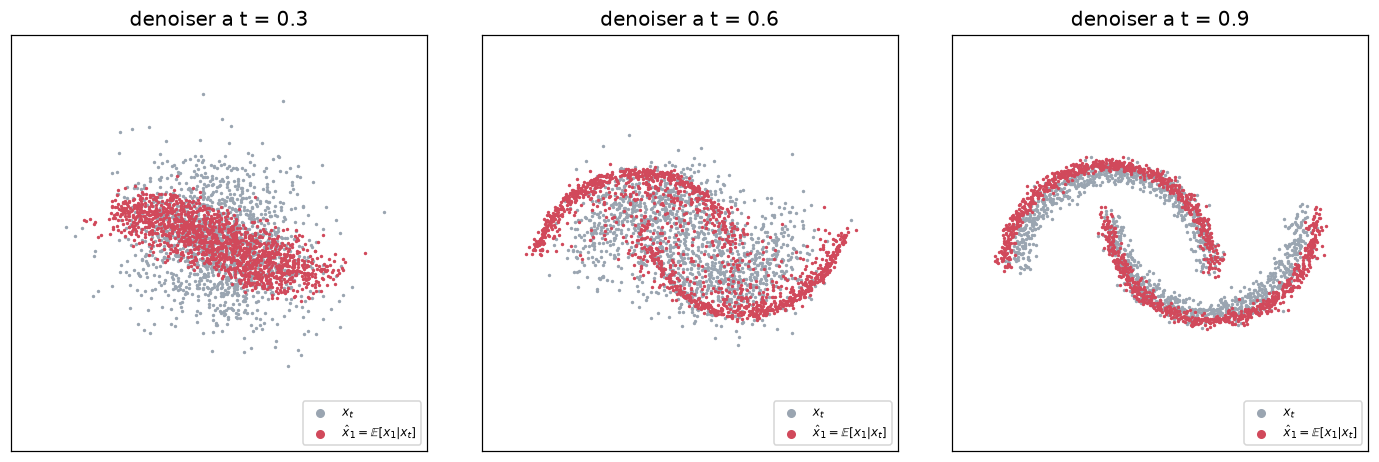

In [10]:
@torch.no_grad()
def predictions(model, xt, t):
    tt = torch.full((xt.shape[0],), t, device=device)
    v = model(xt.to(device), tt).cpu()
    x0_hat = xt - t * v
    x1_hat = xt + (1 - t) * v
    score = -x0_hat / (1 - t)
    return v, x0_hat, x1_hat, score

# (a) denoiser: a partir de x_t ruidoso, ¿a qué dato apunta el modelo?
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
x1 = sample_data(1500); x0 = torch.randn_like(x1)
for ax, t in zip(axs, [0.3, 0.6, 0.9]):
    xt = (1 - t) * x0 + t * x1
    _, _, x1_hat, _ = predictions(model, xt, t)
    ax.scatter(*xt.T, s=1.5, c=C_NOISE, label="$x_t$")
    ax.scatter(*x1_hat.T, s=1.5, c=C_DATA, label=r"$\hat x_1 = \mathbb{E}[x_1|x_t]$")
    ax.set_title(f"denoiser a t = {t}"); ax.legend(loc="lower right", fontsize=8, markerscale=4)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("nb1_denoiser"); plt.show()

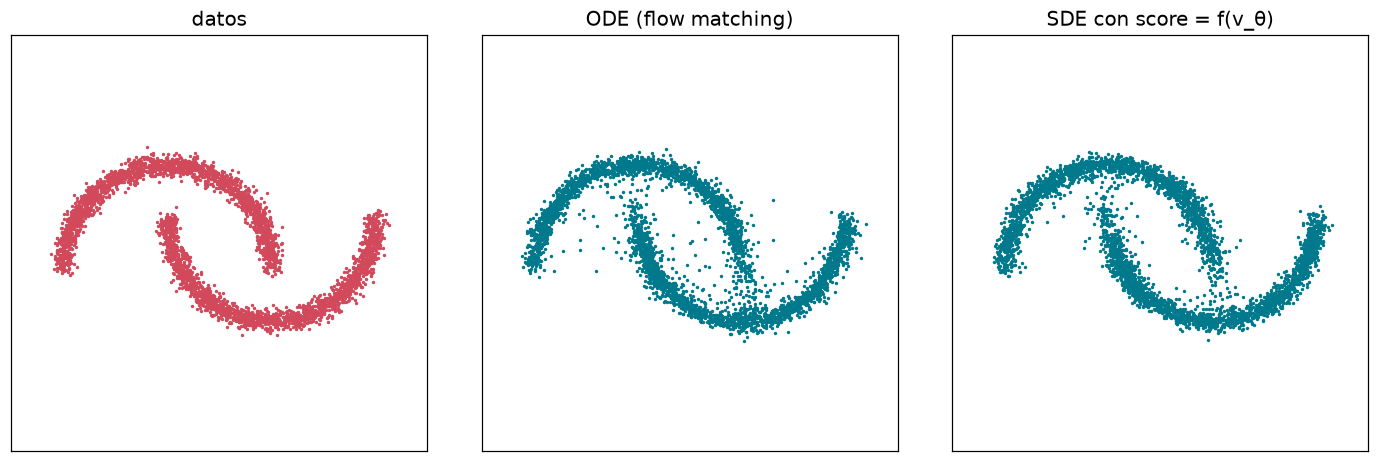

SW(ODE, datos) = 0.0544 | SW(SDE, datos) = 0.0441


In [11]:
# (b) muestreo estocástico (SDE) con el score derivado de la velocidad
@torch.no_grad()
def sample_sde(model, x0, steps=200, g_scale=1.0, t_max=0.98):
    x, h = x0.clone(), t_max / steps
    for i in range(steps):
        t = i * h
        v, _, _, score = predictions(model, x, t)
        g = g_scale * math.sqrt(1 - t)   # menos ruido según nos acercamos a los datos
        x = x + h * (v + 0.5 * g**2 * score) + g * math.sqrt(h) * torch.randn_like(x)
    # último tramo determinista hasta t=1
    _, _, x1_hat, _ = predictions(model, x, t_max)
    return x1_hat

z = torch.randn(4000, 2)
x_ode = sample_ode(model, z, steps=100)
x_sde = sample_sde(model, z, steps=200, g_scale=1.0)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (x, ttl) in zip(axs, [(sample_data(4000), "datos"), (x_ode, "ODE (flow matching)"), (x_sde, "SDE con score = f(v_θ)")]):
    ax.scatter(*x.T, s=1.5, c=C_DATA if ttl == "datos" else C_TRAJ); ax.set_title(ttl)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); savefig("nb1_ode_vs_sde"); plt.show()
print("SW(ODE, datos) =", round(sliced_wasserstein(x_ode, sample_data(4000)), 4),
      "| SW(SDE, datos) =", round(sliced_wasserstein(x_sde, sample_data(4000)), 4))

**Mensaje clave:** Flow Matching con caminos gaussianos y los modelos de difusión entrenan, en el fondo, **el mismo modelo**. Lo que cambia es:
- el **camino/schedule** $(\alpha_t, \sigma_t)$ — FM permite elegir uno recto ($\alpha_t=t,\ \sigma_t=1-t$);
- la **parametrización** de la salida (velocidad vs. ruido vs. score) y la **ponderación** de la pérdida en $t$;
- el **muestreador** (ODE determinista vs. SDE).

## 9. Ejercicios propuestos

1. **Otros datos.** Cambia `sample_data` a `"checkerboard"` u `"8 gaussianas"` y repite. ¿Qué dataset necesita más NFE? ¿Por qué?
2. **Muestreo de $t$.** Stable Diffusion 3 muestrea $t$ con una *logit-normal* en lugar de uniforme (más peso a tiempos intermedios). Implementa `t = torch.sigmoid(torch.randn(batch))` y compara la curva calidad–NFE.
3. **Camino VP (difusión).** Sustituye la interpolación lineal por $x_t = \alpha_t x_1 + \sigma_t x_0$ con $\alpha_t=\sin(\tfrac{\pi}{2}t)$, $\sigma_t=\cos(\tfrac{\pi}{2}t)$ y objetivo $\dot\alpha_t x_1 + \dot\sigma_t x_0$. ¿Son las trayectorias más o menos curvas?
4. **$\sigma_{\min}$.** Lipman et al. usan $x_t = (1-(1-\sigma_{\min})t)\,x_0 + t\,x_1$. Implementa el objetivo correspondiente.
5. **Ruido en la SDE.** Varía `g_scale` en `sample_sde` (0, 0.5, 2). ¿Qué pasa con pocos pasos?